<a href="https://colab.research.google.com/github/jenifelix/Isolation_Forest/blob/main/IF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest


In [2]:
np.random.seed(42)

In [3]:
amount = np.random.normal(1000, 200, 100)
time = np.random.normal(12, 2, 100)

In [4]:
outlier_amount = np.array([4000, 5000, 4500, 6000, 5500])
outlier_time = np.array([2, 23, 3, 22, 1])

In [5]:
amount = np.concatenate([amount, outlier_amount])
time = np.concatenate([time, outlier_time])

In [6]:
data = pd.DataFrame({
    'Transaction_Amount': amount,
    'Transaction_Time': time
})

In [7]:
print("Sample Dataset:")
print(data.tail(10))

Sample Dataset:
     Transaction_Amount  Transaction_Time
95           707.297010         12.770635
96          1059.224055         10.232285
97          1052.211054         12.307450
98          1001.022691         12.116417
99           953.082573          9.714059
100         4000.000000          2.000000
101         5000.000000         23.000000
102         4500.000000          3.000000
103         6000.000000         22.000000
104         5500.000000          1.000000


In [8]:
model = IsolationForest(
    contamination=0.05,
    random_state=42
)

data['Anomaly'] = model.fit_predict(
    data[['Transaction_Amount', 'Transaction_Time']]
)

In [9]:
data['Result'] = data['Anomaly'].map({
    1: 'Normal',
    -1: 'Anomaly'
})

print("\nAnomaly Detection Results:")
print(data.tail(10))


Anomaly Detection Results:
     Transaction_Amount  Transaction_Time  Anomaly   Result
95           707.297010         12.770635        1   Normal
96          1059.224055         10.232285        1   Normal
97          1052.211054         12.307450        1   Normal
98          1001.022691         12.116417        1   Normal
99           953.082573          9.714059        1   Normal
100         4000.000000          2.000000       -1  Anomaly
101         5000.000000         23.000000       -1  Anomaly
102         4500.000000          3.000000       -1  Anomaly
103         6000.000000         22.000000       -1  Anomaly
104         5500.000000          1.000000       -1  Anomaly


In [10]:
print("\nSummary:")
print(data['Result'].value_counts())


Summary:
Result
Normal     99
Anomaly     6
Name: count, dtype: int64


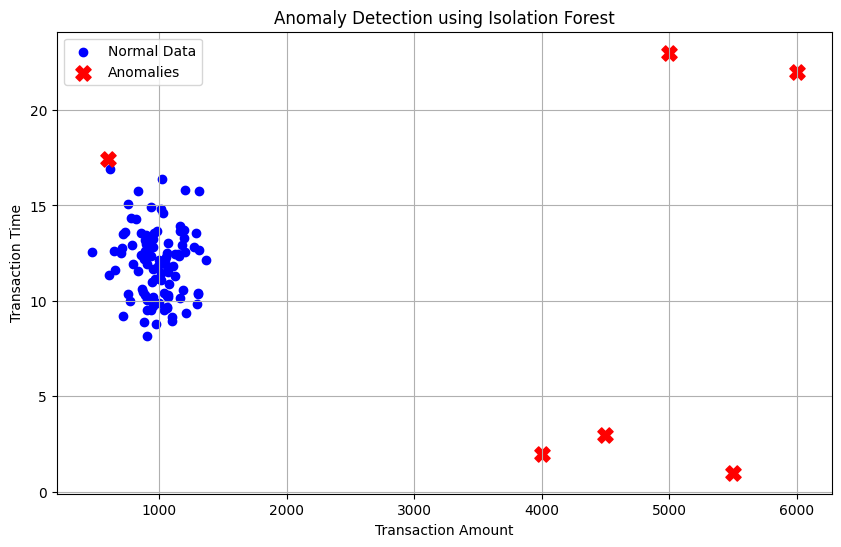

In [11]:
plt.figure(figsize=(10, 6))

normal = data[data['Anomaly'] == 1]
anomaly = data[data['Anomaly'] == -1]

plt.scatter(
    normal['Transaction_Amount'],
    normal['Transaction_Time'],
    color='blue',
    label='Normal Data'
)

plt.scatter(
    anomaly['Transaction_Amount'],
    anomaly['Transaction_Time'],
    color='red',
    marker='X',
    s=120,
    label='Anomalies'
)

plt.xlabel('Transaction Amount')
plt.ylabel('Transaction Time')
plt.title('Anomaly Detection using Isolation Forest')

plt.legend()
plt.grid(True)
plt.show()
